# Delta hedging Analysis

**Question.** Does a calibrated stochastic-volatility model improve one-day option hedges?


In [1]:
from collections import namedtuple
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import least_squares
from scipy.stats import norm


RISK_FREE_RATE = 0.03
DIVIDEND_YIELD = 0.013
REAL_WORLD_DRIFT = 0.07
TRADING_DAY = 1 / 252

HESTON_PARAMS = {
    "v0": 0.04,
    "kappa": 2.0,
    "theta": 0.04,
    "xi": 0.6,
    "rho": -0.7,
}

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)

plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.3,
    }
)

## 1. Black–Scholes Model

$$C = S e^{-q\tau}N(d_1) - K e^{-r\tau}N(d_2), \qquad d_{1,2} = \frac{\ln(S/K) + (r - q \pm \sigma^2/2)\tau}{\sigma\sqrt\tau},$$

with $\Delta = e^{-q\tau}\big(N(d_1) - \mathbb 1_{\text{put}}\big)$ and $\mathcal V = S e^{-q\tau}\varphi(d_1)\sqrt\tau$. 

In [2]:
def _d12(S, K, tau, sigma, risk_free_rate, dividend_yield):
    """Return the Black–Scholes d1 and d2 values."""
    sigma_root_tau = sigma * np.sqrt(tau)
    d1 = (
        np.log(S / K)
        + (risk_free_rate - dividend_yield + 0.5 * sigma**2) * tau
    ) / sigma_root_tau
    return d1, d1 - sigma_root_tau


def bs_price(
    S, K, tau, sigma, call=True,
    risk_free_rate=RISK_FREE_RATE,
    dividend_yield=DIVIDEND_YIELD,
):
    """Price a European call or put with the Black–Scholes model."""
    d1, d2 = _d12(S, K, tau, sigma, risk_free_rate, dividend_yield)
    call_price = (
        S * np.exp(-dividend_yield * tau) * norm.cdf(d1)
        - K * np.exp(-risk_free_rate * tau) * norm.cdf(d2)
    )
    put_price = (
        call_price
        - S * np.exp(-dividend_yield * tau)
        + K * np.exp(-risk_free_rate * tau)
    )
    return np.where(call, call_price, put_price)


def bs_delta(
    S, K, tau, sigma, call=True,
    risk_free_rate=RISK_FREE_RATE,
    dividend_yield=DIVIDEND_YIELD,
):
    """Return the spot delta for a European call or put."""
    d1, _ = _d12(S, K, tau, sigma, risk_free_rate, dividend_yield)
    call_delta = np.exp(-dividend_yield * tau) * norm.cdf(d1)
    put_delta = call_delta - np.exp(-dividend_yield * tau)
    return np.where(call, call_delta, put_delta)


def bs_vega(
    S, K, tau, sigma,
    risk_free_rate=RISK_FREE_RATE,
    dividend_yield=DIVIDEND_YIELD,
):
    """Return the derivative of the option price with respect to volatility."""
    d1, _ = _d12(S, K, tau, sigma, risk_free_rate, dividend_yield)
    return S * np.exp(-dividend_yield * tau) * norm.pdf(d1) * np.sqrt(tau)


def implied_vol(
    price, S, K, tau, call=True,
    risk_free_rate=RISK_FREE_RATE,
    dividend_yield=DIVIDEND_YIELD,
    lo=1e-4,
    hi=5.0,
    n=100,
):
    """Invert Black–Scholes prices by vectorized bisection."""
    price, S, K, tau, call, risk_free_rate, dividend_yield = np.broadcast_arrays(
        price, S, K, tau, call, risk_free_rate, dividend_yield
    )
    lower = np.full(price.shape, lo)
    upper = np.full(price.shape, hi)

    for _ in range(n):
        midpoint = (lower + upper) / 2
        below_market_price = (
            bs_price(
                S, K, tau, midpoint, call,
                risk_free_rate, dividend_yield,
            )
            < price
        )
        lower = np.where(below_market_price, midpoint, lower)
        upper = np.where(below_market_price, upper, midpoint)

    price_at_lower = bs_price(
        S, K, tau, lo, call, risk_free_rate, dividend_yield
    )
    price_at_upper = bs_price(
        S, K, tau, hi, call, risk_free_rate, dividend_yield
    )
    is_bracketed = (price_at_lower <= price) & (price <= price_at_upper)
    return np.where(is_bracketed, (lower + upper) / 2, np.nan)


In [3]:
# Put–call parity and finite differences check the implementation independently.
test_strikes = np.array([80.0, 100.0, 120.0])
test_maturity, test_volatility, step = 0.5, 0.2, 1e-4
call_prices = bs_price(100, test_strikes, test_maturity, test_volatility)
put_prices = bs_price(100, test_strikes, test_maturity, test_volatility, call=False)
parity_value = (
    100 * np.exp(-DIVIDEND_YIELD * test_maturity)
    - test_strikes * np.exp(-RISK_FREE_RATE * test_maturity)
)
assert np.allclose(call_prices - put_prices, parity_value)

finite_difference_delta = (
    bs_price(100 + step, test_strikes, test_maturity, test_volatility)
    - bs_price(100 - step, test_strikes, test_maturity, test_volatility)
) / (2 * step)
assert np.allclose(
    finite_difference_delta,
    bs_delta(100, test_strikes, test_maturity, test_volatility),
)

finite_difference_vega = (
    bs_price(100, test_strikes, test_maturity, test_volatility + step)
    - bs_price(100, test_strikes, test_maturity, test_volatility - step)
) / (2 * step)
assert np.allclose(
    finite_difference_vega,
    bs_vega(100, test_strikes, test_maturity, test_volatility),
)

test_volatilities = np.array([0.35, 0.20, 0.15])
observed_prices = bs_price(100, test_strikes, test_maturity, test_volatilities)
assert np.allclose(
    implied_vol(observed_prices, 100, test_strikes, test_maturity),
    test_volatilities,
)

## 2. Heston 

### SDE:
$$dS_t = (r-q)S_t\,dt + \sqrt{v_t}S_t\,dW^S_t,$$ $$\;dv_t = \kappa(\theta - v_t)\,dt + \xi\sqrt{v_t}\,dW^v_t,$$ $$\;d\langle W^S, W^v\rangle_t = \rho\,dt.$$
For $X_\tau = \ln(S_\tau/F_\tau)$, prices follow from Lewis (2001):

$$C = Se^{-q\tau} - \frac{\sqrt{SK}\,e^{-(r+q)\tau/2}}{\pi}\int_0^\infty \frac{\operatorname{Re}\!\big[e^{iuk}\,\mathbb E[e^{i(u - i/2)X_\tau}]\big]}{u^2 + 1/4}\,du, \qquad k = \ln\frac SK + (r-q)\tau.$$

Differentiating under the integral gives $\partial_S C$ and $\partial_{v}C$ (the latter brings down a factor $B$). The **minimum-variance delta** is

$$\Delta_{MV} = \partial_S C + \frac{\rho\,\xi}{S}\,\partial_v C.$$



In [4]:
_quadrature_nodes, _quadrature_weights = np.polynomial.legendre.leggauss(512)
_quadrature_nodes = (_quadrature_nodes + 1) / 2
_quadrature_weights = _quadrature_weights / 2

Greeks = namedtuple("Greeks", "C delta dCdv mv")


def heston_AB(u, tau, kappa, theta, xi, rho):
    """Return the little-trap affine coefficients for the Heston model."""
    b = kappa - rho * xi * 1j * u
    d = np.sqrt(b**2 + xi**2 * (u**2 + 1j * u))
    g = (b - d) / (b + d)
    exp_minus_dt = np.exp(-d * tau)

    A = (kappa * theta / xi**2) * (
        (b - d) * tau
        - 2 * np.log((1 - g * exp_minus_dt) / (1 - g))
    )
    B = (b - d) / xi**2 * (1 - exp_minus_dt) / (1 - g * exp_minus_dt)
    return A, B


def heston(
    S, K, tau, v0, kappa, theta, xi, rho, call=True,
    risk_free_rate=RISK_FREE_RATE,
    dividend_yield=DIVIDEND_YIELD,
):
    """Price European options and return spot and variance sensitivities."""
    S, K, tau, v0, call, risk_free_rate, dividend_yield = (
        np.asarray(value, dtype=float)
        for value in np.broadcast_arrays(
            S, K, tau, v0, call, risk_free_rate, dividend_yield
        )
    )
    if np.any(tau <= 0):
        raise ValueError("Heston pricing requires strictly positive time to expiry.")

    if abs(xi) < 1e-8:
        # With zero vol-of-vol, variance follows its deterministic mean-reverting path.
        integrated_variance = (
            theta * tau
            + (v0 - theta) * (-np.expm1(-kappa * tau)) / kappa
        )
        effective_volatility = np.sqrt(integrated_variance / tau)
        price = bs_price(
            S, K, tau, effective_volatility, call,
            risk_free_rate, dividend_yield,
        )
        delta = bs_delta(
            S, K, tau, effective_volatility, call,
            risk_free_rate, dividend_yield,
        )
        variance_sensitivity = (
            bs_vega(
                S, K, tau, effective_volatility,
                risk_free_rate, dividend_yield,
            )
            * (-np.expm1(-kappa * tau))
            / (2 * kappa * tau * effective_volatility)
        )
        mv_delta = delta + rho * xi / S * variance_sensitivity
        return Greeks(price, delta, variance_sensitivity, mv_delta)

    L = 10 / np.sqrt(np.maximum(np.minimum(v0, theta), 1e-4) * tau)
    u = L[..., None] * _quadrature_nodes / (1 - _quadrature_nodes)
    weights = L[..., None] * _quadrature_weights / (1 - _quadrature_nodes) ** 2
    A, B = heston_AB(u - 0.5j, tau[..., None], kappa, theta, xi, rho)
    log_forward_moneyness = np.log(S / K) + (risk_free_rate - dividend_yield) * tau
    integrand = np.exp(
        1j * u * log_forward_moneyness[..., None] + A + B * v0[..., None]
    ) / (u**2 + 0.25)

    def integrate(values):
        return (values.real * weights).sum(axis=-1)

    scale = np.sqrt(S * K) * np.exp(
        -(risk_free_rate + dividend_yield) * tau / 2
    ) / np.pi
    dividend_discount = np.exp(-dividend_yield * tau)

    call_price = S * dividend_discount - scale * integrate(integrand)
    call_delta = dividend_discount - scale / S * integrate(
        integrand * (0.5 + 1j * u)
    )
    variance_sensitivity = -scale * integrate(integrand * B)

    put = call == 0
    price = np.where(
        put,
        call_price - S * dividend_discount + K * np.exp(-risk_free_rate * tau),
        call_price,
    )
    delta = np.where(put, call_delta - dividend_discount, call_delta)
    mv_delta = delta + rho * xi / S * variance_sensitivity
    return Greeks(price, delta, variance_sensitivity, mv_delta)


def simulate_heston(
    S0, v0, kappa, theta, xi, rho, T, n, m, rng,
    real_world_drift=REAL_WORLD_DRIFT,
    dividend_yield=DIVIDEND_YIELD,
):
    """Simulate Heston paths with full-truncation Euler and antithetic draws."""
    if n <= 0:
        raise ValueError("n must be a positive number of time steps.")
    if m <= 0:
        raise ValueError("m must be a positive number of paths.")

    step = T / n
    stock = np.empty((n + 1, m))
    variance = np.empty((n + 1, m))
    stock[0] = S0
    variance[0] = v0

    for i in range(n):
        half = (m + 1) // 2
        normals = rng.standard_normal((2, half))
        normals = np.concatenate((normals, -normals), axis=1)[:, :m]
        z_variance, z_independent = normals

        variance_for_step = np.maximum(variance[i], 0)
        correlated_stock_shock = (
            rho * z_variance + np.sqrt(1 - rho**2) * z_independent
        )
        stock[i + 1] = stock[i] * np.exp(
            (real_world_drift - dividend_yield - variance_for_step / 2) * step
            + np.sqrt(variance_for_step * step) * correlated_stock_shock
        )
        variance[i + 1] = (
            variance[i]
            + kappa * (theta - variance_for_step) * step
            + xi * np.sqrt(variance_for_step * step) * z_variance
        )

    return stock, np.maximum(variance, 0)


## 3. Verification

(i) Heston's original $P_1, P_2$ representation integrated by composite Simpson on $6\cdot 10^5$ nodes; 

(ii) the limit $\xi \to 0$, $v_0 = \theta$, which is Black–Scholes with $\sigma = \sqrt\theta$; 

(iii) $\partial_S C$, $\partial_v C$ against central differences; 

(iv) Monte Carlo with $10^5$ paths.

In [5]:
def heston_reference(S, K, tau, v0, kappa, theta, xi, rho,
                     n=600_001, umax=3000.0):
    """Price a European option with Heston's original two-integral formula."""
    u = np.linspace(1e-9, umax, n)
    step = u[1] - u[0]
    probabilities = []

    for power, b0 in ((0.5, kappa - rho * xi), (-0.5, kappa)):
        a = b0 - rho * xi * 1j * u
        d = np.sqrt(a**2 - xi**2 * (2 * power * 1j * u - u**2))
        g = (a - d) / (a + d)
        exp_minus_dt = np.exp(-d * tau)
        C = (
            (RISK_FREE_RATE - DIVIDEND_YIELD) * 1j * u * tau
            + kappa * theta / xi**2
            * ((a - d) * tau - 2 * np.log((1 - g * exp_minus_dt) / (1 - g)))
        )
        D = (a - d) / xi**2 * (1 - exp_minus_dt) / (1 - g * exp_minus_dt)
        integrand = (
            np.exp(C + D * v0 + 1j * u * np.log(S / K)) / (1j * u)
        ).real
        integral = step / 3 * (
            integrand[0]
            + integrand[-1]
            + 4 * integrand[1:-1:2].sum()
            + 2 * integrand[2:-1:2].sum()
        )
        probabilities.append(0.5 + integral / np.pi)

    return (
        S * np.exp(-DIVIDEND_YIELD * tau) * probabilities[0]
        - K * np.exp(-RISK_FREE_RATE * tau) * probabilities[1]
    )


K = np.array([70.0, 85.0, 100.0, 115.0, 130.0])
err_ref = max(
    abs(heston(100, strike, tau, **HESTON_PARAMS).C
        - heston_reference(100, strike, tau, **HESTON_PARAMS))
    for tau in (1 / 52, 0.25, 1.0)
    for strike in K
)
low_vol_of_vol = dict(v0=0.04, kappa=1.0, theta=0.04, xi=1e-4, rho=0.0)
err_bs = max(
    abs(heston(100, K, tau, **low_vol_of_vol).C - bs_price(100, K, tau, 0.2)).max()
    for tau in (0.05, 0.5, 2.0)
)

spot_step = 1e-4
params_up = dict(HESTON_PARAMS, v0=HESTON_PARAMS["v0"] + 1e-6)
params_down = dict(HESTON_PARAMS, v0=HESTON_PARAMS["v0"] - 1e-6)
for is_call in (True, False):
    greeks = heston(100, K, 0.5, **HESTON_PARAMS, call=is_call)
    spot_delta_fd = (
        heston(100 + spot_step, K, 0.5, **HESTON_PARAMS, call=is_call).C
        - heston(100 - spot_step, K, 0.5, **HESTON_PARAMS, call=is_call).C
    ) / (2 * spot_step)
    variance_delta_fd = (
        heston(100, K, 0.5, **params_up, call=is_call).C
        - heston(100, K, 0.5, **params_down, call=is_call).C
    ) / 2e-6
    assert np.allclose(greeks.delta, spot_delta_fd, atol=1e-7)
    assert np.allclose(greeks.dCdv, variance_delta_fd, atol=1e-5)

terminal_stock = simulate_heston(
    100, *HESTON_PARAMS.values(), T=1.0, n=250, m=100_000,
    rng=np.random.default_rng(1), real_world_drift=RISK_FREE_RATE,
)[0][-1]
z_scores = {}
for is_call, sign in ((True, 1), (False, -1)):
    payoffs = np.exp(-RISK_FREE_RATE) * np.maximum(
        sign * (terminal_stock[:, None] - K), 0
    )
    model_price = heston(100, K, 1.0, **HESTON_PARAMS, call=is_call).C
    standard_error = payoffs.std(0) / np.sqrt(len(terminal_stock))
    z_scores[is_call] = (payoffs.mean(0) - model_price) / standard_error

print(f"|Lewis - reference| <= {err_ref:.1e}, "
      f"|Heston(xi->0) - BS| <= {err_bs:.1e}")
print("Monte Carlo z-scores, calls:", z_scores[True].round(2),
      "puts:", z_scores[False].round(2))
assert err_ref < 1e-5 and err_bs < 1e-5
assert all(np.abs(scores).max() < 3.5 for scores in z_scores.values())


|Lewis - reference| <= 4.6e-09, |Heston(xi->0) - BS| <= 6.4e-08
Monte Carlo z-scores, calls: [-0.02 -0.32 -0.49  0.53  0.38] puts: [ 0.66 -0.18 -0.14  0.34  0.21]


## 4. The smile as a function of $(\rho, \xi)$ 


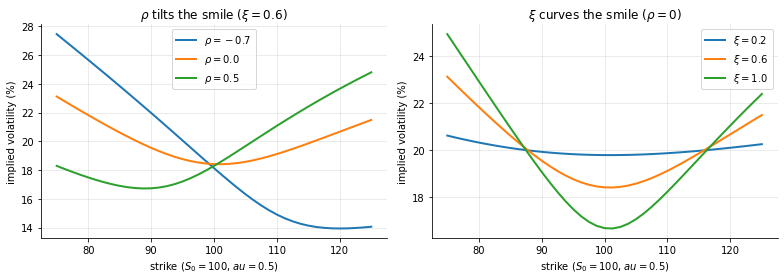

In [6]:
K, tau = np.linspace(75, 125, 41), 0.5
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for rho_value in (-0.7, 0.0, 0.5):
    prices = heston(100, K, tau, **dict(HESTON_PARAMS, rho=rho_value)).C
    volatilities = implied_vol(prices, 100, K, tau)
    ax[0].plot(K, 100 * volatilities, lw=2, label=fr"$\rho={rho_value}$")

for xi_value in (0.2, 0.6, 1.0):
    params = dict(HESTON_PARAMS, xi=xi_value, rho=0.0)
    prices = heston(100, K, tau, **params).C
    volatilities = implied_vol(prices, 100, K, tau)
    ax[1].plot(K, 100 * volatilities, lw=2, label=fr"$\xi={xi_value}$")

ax[0].set_title(r"$\rho$ tilts the smile ($\xi=0.6$)")
ax[1].set_title(r"$\xi$ curves the smile ($\rho=0$)")
for axis in ax:
    axis.set(
        xlabel="strike ($S_0=100$, $\tau=0.5$)",
        ylabel="implied volatility (%)",
    )
    axis.legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "smile_parameters.png", dpi=150)
plt.show()


## 5. A worked option example

Fix $S_0=K=100$, $\tau=0.25$, $r=3\%$, and $q=1.3\%$. The reference Heston parameters are $v_0=\theta=0.04$, $\kappa=2$, $\xi=0.6$, and $\rho=-0.7$. The Heston price determines an implied volatility at which the Black–Scholes price agrees. The two models can therefore have the same initial price and different hedge ratios.


In [7]:
Sx, Kx, tx = 100.0, 100.0, 0.25
G0 = heston(Sx, Kx, tx, **HESTON_PARAMS)
sig = float(implied_vol(G0.C, Sx, Kx, tx))
d1 = float(_d12(Sx, Kx, tx, sig, RISK_FREE_RATE, DIVIDEND_YIELD)[0])
dBS = float(bs_delta(Sx, Kx, tx, sig))
vBS = float(bs_vega(Sx, Kx, tx, sig))
call_price = float(bs_price(Sx, Kx, tx, sig))
put_price = float(bs_price(Sx, Kx, tx, sig, call=False))

print(
    f"Heston price {float(G0.C):.4f} = BS price at sigma_imp {call_price:.4f}; "
    f"put {put_price:.4f}; sigma_imp = {sig:.4%}"
)
print(
    f"d1 = {d1:.4f}, Phi(d1) = {norm.cdf(d1):.4f}, "
    f"Delta_BS = {dBS:.4f}, vega_BS = {vBS:.2f}"
)
print(
    f"Heston: dC/dS = {float(G0.delta):.4f}, "
    f"dC/dv = {float(G0.dCdv):.2f}, Delta_MV = {float(G0.mv):.4f}"
)

terminal_prices = np.array([80.0, 100.0, 120.0])
payoffs = pd.DataFrame(
    {
        "call payoff": np.maximum(terminal_prices - Kx, 0),
        "call profit": np.maximum(terminal_prices - Kx, 0) - call_price,
        "put payoff": np.maximum(Kx - terminal_prices, 0),
        "put profit": np.maximum(Kx - terminal_prices, 0) - put_price,
    },
    index=terminal_prices,
).T
print(payoffs.round(2))

Heston price 3.9234 = BS price at sigma_imp 3.9234; put 3.5007; sigma_imp = 18.6972%
d1 = 0.0922, Phi(d1) = 0.5367, Delta_BS = 0.5350, vega_BS = 19.80
Heston: dC/dS = 0.6284, dC/dv = 39.94, Delta_MV = 0.4607
             80.0   100.0  120.0
call payoff   0.00   0.00  20.00
call profit  -3.92  -3.92  16.08
put payoff   20.00   0.00   0.00
put profit   16.50  -3.50  -3.50


### One-day hedge comparison

We hold one **long** three-month call and short $h$ shares and $n$ one-year calls. The one-day error is $e=\Delta C-h\Delta S-n\Delta H$. For a spot move $\Delta S=\pm1$, the variance change is set to $\Delta v=(\rho\xi/S_0)\Delta S$. Both options are repriced with one trading day less to expiry. The displayed errors omit the small one-day cash and dividend carry terms.

The Hull–White correction uses coefficients fitted by least squares on the first 100 paths of a seeded 200-path, 30-day simulated Heston panel. The panel has five strikes at each of two maturities; the option prices, Black–Scholes implied volatilities, deltas, and vegas are computed at each hedge date. The coefficients are estimated from that panel in the next cell, then applied to the worked call. This is a synthetic calculation, separate from the Yahoo Finance example.

In [8]:
def fit_hull_white_coefficients(n_paths=200, n_days=30, substeps=4, seed=7):
    """Fit the delta correction using hedging errors on simulated paths."""
    strike_ratios = np.array([0.90, 0.95, 1.00, 1.05, 1.10])
    strikes = 100 * np.tile(strike_ratios, 2)
    initial_maturities = np.repeat([0.25, 0.50], len(strike_ratios))
    is_call = strikes >= 100

    stock, variance = simulate_heston(
        100.0,
        *HESTON_PARAMS.values(),
        T=n_days * TRADING_DAY,
        n=n_days * substeps,
        m=n_paths,
        rng=np.random.default_rng(seed),
    )
    stock = stock[::substeps].T[:, None, :]
    variance = variance[::substeps].T[:, None, :]

    price_history, delta_history, vega_history = [], [], []
    for day in range(n_days + 1):
        spot = stock[..., day]
        time_to_expiry = initial_maturities - day * TRADING_DAY
        prices = heston(
            spot, strikes, time_to_expiry, variance[..., day],
            *list(HESTON_PARAMS.values())[1:], call=is_call,
        ).C
        iv = implied_vol(prices, spot, strikes, time_to_expiry, is_call)
        price_history.append(prices)
        delta_history.append(bs_delta(spot, strikes, time_to_expiry, iv, is_call))
        vega_history.append(bs_vega(spot, strikes, time_to_expiry, iv))

    prices = np.stack(price_history, axis=-1)
    deltas = np.stack(delta_history, axis=-1)[..., :-1]
    vegas = np.stack(vega_history, axis=-1)[..., :-1]
    spot_now = stock[..., :-1]
    spot_change = np.diff(stock, axis=-1)
    time_to_expiry = (
        initial_maturities[:, None] - np.arange(n_days) * TRADING_DAY
    )

    # Self-financing error of the Black–Scholes stock hedge.
    bs_error = (
        np.diff(prices, axis=-1)
        - deltas * spot_change
        - RISK_FREE_RATE * TRADING_DAY * (prices[..., :-1] - deltas * spot_now)
        - deltas * DIVIDEND_YIELD * spot_now * TRADING_DAY
    )
    exposure = vegas * spot_change / (spot_now * np.sqrt(time_to_expiry))
    call_equivalent_delta = np.where(
        is_call[:, None],
        deltas,
        deltas + np.exp(-DIVIDEND_YIELD * time_to_expiry),
    )
    design = np.stack(
        [
            exposure,
            exposure * call_equivalent_delta,
            exposure * call_equivalent_delta**2,
        ],
        axis=-1,
    )

    training_paths = slice(0, n_paths // 2)
    return np.linalg.lstsq(
        design[training_paths].reshape(-1, 3),
        bs_error[training_paths].ravel(),
        rcond=None,
    )[0]


hw_coefficients = fit_hull_white_coefficients()
print("Fitted Hull–White coefficients (a, b, c):", hw_coefficients.round(3))

Fitted Hull–White coefficients (a, b, c): [-0.305  0.386 -0.279]


In [9]:
# Each hedge is a position (h, n): short h shares and n one-year calls.
hedge_call = heston(Sx, Kx, 1.0, **HESTON_PARAMS)
hedge_iv = float(implied_vol(hedge_call.C, Sx, Kx, 1.0))
hedge_bs_delta = float(bs_delta(Sx, Kx, 1.0, hedge_iv))
hedge_bs_vega = float(bs_vega(Sx, Kx, 1.0, hedge_iv))

a, b, c = hw_coefficients
hw_shares = dBS + vBS / (Sx * np.sqrt(tx)) * (a + b * dBS + c * dBS**2)

bs_hedge_calls = vBS / hedge_bs_vega
bs_hedge_shares = dBS - bs_hedge_calls * hedge_bs_delta
heston_hedge_calls = float(G0.dCdv / hedge_call.dCdv)
heston_hedge_shares = float(G0.delta - heston_hedge_calls * hedge_call.delta)

hedges = [
    ("Unhedged", 0.0, 0.0),
    ("1  Black–Scholes Δ_BS", dBS, 0.0),
    ("2  Heston ∂_S C", float(G0.delta), 0.0),
    ("3  Heston Δ_MV", float(G0.mv), 0.0),
    ("4  Hull–White Δ_HW", hw_shares, 0.0),
    ("BS delta–vega", bs_hedge_shares, bs_hedge_calls),
    ("Heston delta–vega", heston_hedge_shares, heston_hedge_calls),
]


def one_day_option_changes(spot_change):
    """Reprice the target and hedge calls after a correlated variance shock."""
    next_spot = Sx + spot_change
    next_variance = (
        HESTON_PARAMS["v0"]
        + HESTON_PARAMS["rho"] * HESTON_PARAMS["xi"] * spot_change / Sx
    )
    next_params = dict(HESTON_PARAMS, v0=next_variance)
    target_change = float(
        heston(next_spot, Kx, tx - TRADING_DAY, **next_params).C - G0.C
    )
    hedge_change = float(
        heston(next_spot, Kx, 1.0 - TRADING_DAY, **next_params).C
        - hedge_call.C
    )
    return target_change, hedge_change


scenario_changes = {
    "Error (S up)": (+1.0, *one_day_option_changes(+1.0)),
    "Error (S down)": (-1.0, *one_day_option_changes(-1.0)),
}
rows = []
for name, shares, hedge_calls in hedges:
    row = {"Hedge": name, "Shares h": shares, "One-year calls n": hedge_calls}
    for label, (spot_change, target_change, hedge_change) in scenario_changes.items():
        row[label] = target_change - shares * spot_change - hedge_calls * hedge_change
    rows.append(row)

worked_hedge_table = pd.DataFrame(rows).set_index("Hedge")
formatted_table = worked_hedge_table.copy()
formatted_table["Shares h"] = formatted_table["Shares h"].map("{:.3f}".format)
formatted_table["One-year calls n"] = formatted_table["One-year calls n"].map(
    lambda value: "---" if value == 0 else f"{value:.3f}"
)
for column in ("Error (S up)", "Error (S down)"):
    formatted_table[column] = formatted_table[column].map("{:+.3f}".format)

print(formatted_table.to_string())

                      Shares h One-year calls n Error (S up) Error (S down)
Hedge                                                                      
Unhedged                 0.000              ---       +0.451         -0.471
1  Black–Scholes Δ_BS    0.535              ---       -0.084         +0.064
2  Heston ∂_S C          0.628              ---       -0.177         +0.158
3  Heston Δ_MV           0.461              ---       -0.010         -0.010
4  Hull–White Δ_HW       0.464              ---       -0.013         -0.006
BS delta–vega            0.246            0.511       -0.049         +0.036
Heston delta–vega       -0.050            1.014       -0.002         -0.003


In [10]:
K = np.arange(80.0, 121.0, 5.0)
call = K >= 100
iv_skew = implied_vol(
    heston(Sx, K, tx, **HESTON_PARAMS, call=call).C,
    Sx, K, tx, call,
)
put80 = float(heston(Sx, 80.0, tx, **HESTON_PARAMS, call=False).C)
flat80 = float(bs_price(Sx, 80.0, tx, sig, call=False))

skew_table = pd.DataFrame(
    {"strike": K.astype(int), "implied volatility (%)": (100 * iv_skew).round(1)}
).set_index("strike")
print(skew_table.T.to_string())
print(
    f"80-strike put: {put80:.3f}; at a flat {sig:.1%}: {flat80:.4f}; "
    f"the Heston price is {put80 / flat80:.1f} times the flat-vol price."
)

strike                   80    85    90    95    100   105   110   115   120
implied volatility (%)  27.3  25.3  23.2  21.0  18.7  16.5  15.0  14.5  14.6
80-strike put: 0.239; at a flat 18.7%: 0.0205; the Heston price is 11.7 times the flat-vol price.


## 6. Calibration

Given quotes $C_i^{\mathrm{mkt}}$ with implied volatilities $\sigma_i$, solve

$$\min_{x = (v_0,\kappa,\theta,\xi,\rho)} \sum_i \left(\frac{C_i(x) - C_i^{\mathrm{mkt}}}{\mathcal V_{BS}(\sigma_i)}\right)^2.$$


In [11]:
PARAMETER_NAMES = ["v0", "kappa", "theta", "xi", "rho"]
LOWER_BOUNDS = np.array([1e-4, 0.05, 1e-4, 0.05, -0.999])
UPPER_BOUNDS = np.array([1.0, 15.0, 1.0, 3.0, 0.5])


def calibrate(S, K, tau, price, iv, call, risk_free_rate=RISK_FREE_RATE,
              dividend_yield=DIVIDEND_YIELD, x0=None):
    """Fit Heston parameters to option prices using vega-scaled residuals."""
    vega = np.maximum(
        bs_vega(S, K, tau, iv, risk_free_rate, dividend_yield),
        1e-3 * S,
    )
    if x0 is None:
        median_variance = np.nanmedian(iv) ** 2
        x0 = np.array([median_variance, 1.5, median_variance, 0.5, -0.5])
    initial_guess = np.clip(x0, LOWER_BOUNDS + 1e-6, UPPER_BOUNDS - 1e-6)

    result = least_squares(
        lambda params: (
            heston(
                S, K, tau, *params, call=call,
                risk_free_rate=risk_free_rate,
                dividend_yield=dividend_yield,
            ).C
            - price
        ) / vega,
        initial_guess,
        bounds=(LOWER_BOUNDS, UPPER_BOUNDS),
        x_scale="jac",
        max_nfev=400,
    )
    fit = dict(zip(PARAMETER_NAMES, result.x))
    fit["converged"] = bool(result.success)
    fit["iv_rmse"] = np.sqrt(np.mean(result.fun**2))
    fit["feller"] = 2 * fit["kappa"] * fit["theta"] >= fit["xi"] ** 2
    return fit


K, tau = (grid.ravel() for grid in np.meshgrid(
    np.linspace(80, 120, 9), [1 / 12, 0.25, 0.5, 1.0]
))
call = K >= 100
iv0 = implied_vol(
    heston(100, K, tau, **HESTON_PARAMS, call=call).C,
    100, K, tau, call,
)
rng = np.random.default_rng(3)
fits = []
for _ in range(8):
    noisy_iv = iv0 + 0.003 * rng.standard_normal(iv0.size)
    noisy_prices = bs_price(100, K, tau, noisy_iv, call)
    fits.append(calibrate(100, K, tau, noisy_prices, noisy_iv, call))

fits = pd.DataFrame(fits)
assert abs(fits.v0.mean() - HESTON_PARAMS["v0"]) < 3e-3
assert abs(fits.rho.mean() - HESTON_PARAMS["rho"]) < 0.05
pd.DataFrame(
    {
        "true": HESTON_PARAMS,
        "mean": fits[PARAMETER_NAMES].mean(),
        "std": fits[PARAMETER_NAMES].std(),
    }
).round(4)


,true,mean,std
v0,0.04,0.0397,0.0006
kappa,2.00,1.9797,0.1693
theta,0.04,0.0410,0.0012
xi,0.60,0.6117,0.0262
rho,-0.70,-0.6959,0.0064


In these eight noisy synthetic calibrations, $v_0$ and $\rho$ vary less than $\kappa$; the latter trades off with $\theta$ over the selected maturities. This is a finite-sample observation, not a general identifiability theorem. The reference parameters violate the Feller condition, since $2\kappa\theta=0.16<\xi^2=0.36$.


## 7. An empirical comparison: SPY and AAPL

Consider a near-the-money call on the SPY ETF and one on AAPL stock. We use the same **four completed trading dates** (October 30 and November 2–4, 2026) and the unadjusted daily closes in [SPY history](https://finance.yahoo.com/quote/SPY/history/), [AAPL history](https://finance.yahoo.com/quote/AAPL/history/), [SPY's November 5 $760 call history](https://finance.yahoo.com/quote/SPY261105C00760000/history/), and [AAPL's November 6 $345 call history](https://finance.yahoo.com/quote/AAPL261106C00345000/history/). The option symbols are `SPY261105C00760000` and `AAPL261106C00345000`. All eight recorded option volumes exceed 1,000 contracts. The expiries differ by one calendar day; at the first close the strike-to-spot ratios are approximately 1.006 and 1.001, respectively. The values below are a dated snapshot, so rerunning the notebook does not depend on an API response.

For each observed close, invert the **European** Black–Scholes call formula to get $\widehat\sigma_t$, then compute $\Delta_t^{BS}=\Phi(d_1(S_t,K,T-t,\widehat\sigma_t))$ with $r=q=0$. The zero-rate convention is a short-horizon simplification, not a claim about market rates. A one-contract hedge holds a long call and shorts $h_t=\operatorname{round}(100\Delta_t^{BS})$ borrowed shares. Standard equity and ETF contracts ordinarily cover 100 shares ([OCC equity options](https://www.theocc.com/clearance-and-settlement/clearing/equity-options-product-specifications), [OCC ETF options](https://www.theocc.com/clearance-and-settlement/clearing/etf-options)); adjusted contracts may differ. Both contracts are American-style, and the European delta is therefore an approximation.

If $D_{t,t+1}$ is the per-share cash distribution with ex-date in the interval and $b$ is an assumed annual stock-loan fee, the marked change per contract is

$$\Pi_{t,t+1}=100(C_{t+1}-C_t)-h_t(S_{t+1}-S_t)-h_tD_{t,t+1}-b\,h_tS_t\frac{d}{365},$$

where $d$ is the number of calendar days between observations. The snapshot records zero distributions over these three intervals. We report *gross* hedge errors separately from the illustrative $b=1\%$ borrowing charge; Yahoo does not supply the actual borrow fee or guarantee stock availability. The fourth day's delta is included for completeness, but does not enter an observed next-day hedge.

The single quoted option per asset and date identifies its **Black–Scholes implied volatility and delta**. The Heston spot, minimum-variance, and Hull–White deltas from §5 require a separately calibrated option surface or training sample; they cannot be inferred from these eight call closes. Since implied volatility is obtained by inverting each observed price, matching that same price is automatic. The empirical comparison below concerns *subsequent hedging errors*, not in-sample price fit.

In [12]:
OBSERVATION_DATES = pd.to_datetime(
    ["2026-10-30", "2026-11-02", "2026-11-03", "2026-11-04"]
)
CONTRACT_SHARES = 100

# Historical Yahoo closes and option volumes, transcribed on November 5, 2026.
# Each row of data corresponds to the same date in OBSERVATION_DATES.
contracts = {
    "SPY": {
        "symbol": "SPY261105C00760000",
        "strike": 760.0,
        "expiry": pd.Timestamp("2026-11-05"),
        "spot_close": [755.72, 752.10, 754.35, 766.81],
        "option_close": [4.77, 2.89, 2.89, 8.38],
        "option_volume": [4626, 5320, 5910, 3989],
    },
    "AAPL": {
        "symbol": "AAPL261106C00345000",
        "strike": 345.0,
        "expiry": pd.Timestamp("2026-11-06"),
        "spot_close": [344.63, 338.32, 331.90, 349.51],
        "option_close": [8.25, 5.25, 0.37, 9.75],
        "option_volume": [3478, 3930, 9524, 6735],
    },
}


def historical_quotes(contract):
    """Put the saved Yahoo observations on a common calendar."""
    quotes = pd.DataFrame(
        {column: contract[column] for column in (
            "spot_close", "option_close", "option_volume"
        )},
        index=OBSERVATION_DATES,
    ).rename_axis("date")
    quotes["dividend"] = 0.0  # cash distribution with an ex-date on this date
    return quotes


yahoo_quotes = {
    ticker: historical_quotes(contract) for ticker, contract in contracts.items()
}


def fetch_yahoo_closes(ticker, option_symbol, dates):
    """Optional check against current Yahoo history, via yfinance."""
    try:
        import yfinance as yf
    except ImportError as exc:
        raise ImportError("Install yfinance to refresh Yahoo Finance history.") from exc

    dates = pd.DatetimeIndex(dates).normalize()
    start = dates.min().strftime("%Y-%m-%d")
    end = (dates.max() + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    stock = yf.Ticker(ticker).history(
        start=start, end=end, interval="1d", auto_adjust=False, actions=True
    )
    option = yf.Ticker(option_symbol).history(
        start=start, end=end, interval="1d", auto_adjust=False, actions=False
    )
    if stock.empty or option.empty:
        raise ValueError(f"Yahoo has no complete history for {ticker} and {option_symbol}.")

    stock.index = pd.DatetimeIndex(stock.index).tz_localize(None).normalize()
    option.index = pd.DatetimeIndex(option.index).tz_localize(None).normalize()
    dividend = stock.get("Dividends", pd.Series(0.0, index=stock.index))
    refreshed = pd.concat(
        [
            stock["Close"].rename("spot_close"),
            option["Close"].rename("option_close"),
            option["Volume"].rename("option_volume"),
            dividend.rename("dividend"),
        ],
        axis=1,
    ).reindex(dates)
    if refreshed.isna().any().any():
        raise ValueError(f"Yahoo history is incomplete on the requested {ticker} dates.")
    return refreshed.rename_axis("date")


# To inspect a fresh Yahoo download when yfinance is available:
# refreshed = fetch_yahoo_closes("AAPL", contracts["AAPL"]["symbol"], OBSERVATION_DATES)
# print(refreshed.compare(yahoo_quotes["AAPL"]))
print(pd.concat(yahoo_quotes, names=["ticker", "date"]).to_string())

                   spot_close  option_close  option_volume  dividend
ticker date                                                         
SPY    2026-10-30      755.72          4.77           4626       0.0
       2026-11-02      752.10          2.89           5320       0.0
       2026-11-03      754.35          2.89           5910       0.0
       2026-11-04      766.81          8.38           3989       0.0
AAPL   2026-10-30      344.63          8.25           3478       0.0
       2026-11-02      338.32          5.25           3930       0.0
       2026-11-03      331.90          0.37           9524       0.0
       2026-11-04      349.51          9.75           6735       0.0


In [13]:
def daily_call_deltas(quotes, strike, expiry, contract_shares=100, min_volume=1000):
    """Invert each call close and calculate its same-day stock hedge."""
    if len(quotes) < 2 or not quotes.index.is_unique or not quotes.index.is_monotonic_increasing:
        raise ValueError("Supply at least two observations on distinct increasing dates.")
    if (quotes["option_volume"] < min_volume).any():
        raise ValueError("A call observation fails the stated liquidity cutoff.")
    if not np.isfinite(quotes.to_numpy(dtype=float)).all():
        raise ValueError("Quotes must contain finite prices, volumes, and distributions.")
    if (quotes[["spot_close", "option_close"]] <= 0).any().any():
        raise ValueError("Call and stock closes must be positive.")

    days_to_expiry = (expiry - quotes.index).days.to_numpy()
    if (days_to_expiry <= 0).any():
        raise ValueError("All observations must precede the call expiry.")

    tau = days_to_expiry / 365.0
    iv = implied_vol(
        quotes["option_close"].to_numpy(),
        quotes["spot_close"].to_numpy(),
        strike,
        tau,
        risk_free_rate=0.0,
        dividend_yield=0.0,
    )
    if not np.isfinite(iv).all():
        raise ValueError("A call price has no admissible Black–Scholes volatility.")

    delta = bs_delta(
        quotes["spot_close"].to_numpy(),
        strike,
        tau,
        iv,
        risk_free_rate=0.0,
        dividend_yield=0.0,
    )
    return quotes.assign(
        implied_vol=iv,
        bs_delta=delta,
        shares_borrowed=np.rint(contract_shares * delta).astype(int),
    )


def borrowed_stock_delta_hedge(daily, borrow_fee=0.01, contract_shares=100):
    """Mark a long call and its one-interval, whole-share short stock hedge."""
    if borrow_fee < 0:
        raise ValueError("The assumed annual stock-loan fee must be nonnegative.")

    rows = []
    for entry_date, exit_date in zip(daily.index[:-1], daily.index[1:]):
        entry, exit_quote = daily.loc[entry_date], daily.loc[exit_date]
        days_held = (exit_date - entry_date).days
        shares = int(entry["shares_borrowed"])
        call_change = contract_shares * (
            exit_quote["option_close"] - entry["option_close"]
        )
        stock_change = shares * (
            exit_quote["spot_close"] - entry["spot_close"]
        )
        distribution_owed = shares * exit_quote["dividend"]
        loan_cost = borrow_fee * shares * entry["spot_close"] * days_held / 365
        gross_error = call_change - stock_change

        rows.append({
            "entry": entry_date,
            "exit": exit_date,
            "shares_borrowed": shares,
            "unhedged_pnl": call_change,
            "gross_hedge_pnl": gross_error,
            "dividend_owed": distribution_owed,
            "loan_cost": loan_cost,
            "net_hedge_pnl": gross_error - distribution_owed - loan_cost,
        })

    return pd.DataFrame(rows).set_index("entry")


daily_deltas = {
    ticker: daily_call_deltas(quotes, contracts[ticker]["strike"], contracts[ticker]["expiry"])
    for ticker, quotes in yahoo_quotes.items()
}
hedge_results = {
    ticker: borrowed_stock_delta_hedge(daily, contract_shares=CONTRACT_SHARES)
    for ticker, daily in daily_deltas.items()
}

print("Implied volatility, delta, and borrowed shares on every observed date:")
print(pd.concat(daily_deltas, names=["ticker", "date"])[
    ["spot_close", "option_close", "implied_vol", "bs_delta", "shares_borrowed"]
].round(4).to_string())
print("\nRealized per-contract changes for the three holding intervals:")
print(pd.concat(hedge_results, names=["ticker", "entry"])[
    ["exit", "shares_borrowed", "unhedged_pnl", "gross_hedge_pnl", "loan_cost", "net_hedge_pnl"]
].round(2).to_string())

Implied volatility, delta, and borrowed shares on every observed date:
                   spot_close  option_close  implied_vol  bs_delta  shares_borrowed
ticker date                                                                        
SPY    2026-10-30      755.72          4.77       0.1727    0.4036               40
       2026-11-02      752.10          2.89       0.2207    0.3043               30
       2026-11-03      754.35          2.89       0.2342    0.3366               34
       2026-11-04      766.81          8.38       0.2577    0.7480               75
AAPL   2026-10-30      344.63          8.25       0.4428    0.5052               51
       2026-11-02      338.32          5.25       0.5719    0.3834               38
       2026-11-03      331.90          0.37       0.3108    0.0869                9
       2026-11-04      349.51          9.75       0.7094    0.6078               61

Realized per-contract changes for the three holding intervals:
                        e

In [14]:
def summarize_hedges(hedge_results, daily_deltas, contract_shares=100):
    """Compare errors within each asset before comparing assets."""
    rows = []
    for ticker, hedges in hedge_results.items():
        gross_squared = np.square(hedges["gross_hedge_pnl"]).sum()
        unhedged_squared = np.square(hedges["unhedged_pnl"]).sum()
        initial_premium = contract_shares * daily_deltas[ticker]["option_close"].iloc[0]
        gross_rmse = np.sqrt(gross_squared / len(hedges))
        rows.append({
            "ticker": ticker,
            "intervals": len(hedges),
            "unhedged_rmse_$": np.sqrt(unhedged_squared / len(hedges)),
            "gross_rmse_$": gross_rmse,
            "gross_rmse/initial_premium": gross_rmse / initial_premium,
            "squared_error_reduction": 1 - gross_squared / unhedged_squared,
            "assumed_loan_cost_$": hedges["loan_cost"].sum(),
        })
    return pd.DataFrame(rows).set_index("ticker")


comparison = summarize_hedges(hedge_results, daily_deltas, CONTRACT_SHARES)
print(comparison.round(4).to_string())

        intervals  unhedged_rmse_$  gross_rmse_$  gross_rmse/initial_premium  squared_error_reduction  assumed_loan_cost_$
ticker                                                                                                                    
SPY             3         335.0348       85.9023                      0.1801                   0.9343               3.8054
AAPL            3         634.5571      471.7581                      0.5718                   0.4473               1.8787


**Observed deltas.** For the October 30, November 2, 3, and 4 closes, the SPY call's Black–Scholes deltas are approximately $0.4036, 0.3043, 0.3366, 0.7480$; the AAPL call's are $0.5052, 0.3834, 0.0869, 0.6078$. Multiply by 100 and round to obtain the short-stock positions in the table above. The last delta for each ticker has no subsequent return in this sample.

**Which fits better over these dates?** SPY's gross hedge RMSE falls from **$335.03 to $85.90** per contract, reducing its sum of squared errors by **93.4%**. AAPL's falls from **$634.56 to $471.76**, a **44.7%** reduction. Relative to each contract's *initial option premium*, the gross residual RMSE is **18.0% for SPY** and **57.2% for AAPL**. By either of these within-contract criteria, the SPY call is more closely hedged on these three intervals. Dollar RMSE by itself is not a fair cross-ticker measure. At an assumed annual borrowing fee of 1%, the total modeled fees are **$3.81** (SPY) and **$1.88** (AAPL) per contract over the three intervals; these are not observed financing costs.

The AAPL call starts November 3 far out of the money (USD 331.90 stock, USD 345 strike), with a USD 0.37 option close and a delta near $0.087$. By November 4 the stock closes at USD 349.51 and the call at $9.75$: the one-interval gross hedge error is **+USD 779.51** per contract. A first-order hedge has difficulty with a large move across the strike so near expiry. [Apple reported quarterly results on November 2](https://www.apple.com/newsroom/2026/11/apple-reports-fourth-quarter-results/), an event within the window; these observations alone cannot isolate its effect on the hedge error.

This is a **three-interval illustration**, not a statistical claim that SPY options generally hedge better or that Black–Scholes outperforms another model. Expiries differ by one day, the moneyness paths differ, and Yahoo's option last trades may not be synchronized with the underlying close. The calculation omits bid–ask spreads, actual borrowing terms, financing and exercise effects. Estimating the Heston and Hull–White deltas for these contracts would require a dated cross-section of options and an independent calibration or training period.

## 8. Five underlyings: which hedge works best?

For SPY, QQQ, AAPL, MSFT and TSLA we hedge a long option on every date with five rules and mark the position at the next trading date:

| hedge | shares $h$ | second options $n$ |
|---|---|---|
| Black–Scholes | $\Delta_{BS}(\sigma_{\mathrm{imp}})$ | $0$ |
| Heston | $\partial_S C$ | $0$ |
| Heston minimum variance | $\partial_S C + \frac{\rho\xi}{S}\,\partial_v C$ | $0$ |
| Hull–White | $\Delta_{BS} + \frac{\mathcal V_{BS}}{S\sqrt\tau}\,(a + b\,d + c\,d^2)$ | $0$ |
| Heston delta–vega | $\partial_S C - n\,\partial_S H$ | $n=\partial_v C/\partial_v H$ |

$H$ is a liquid call about a year out. With $\delta t$ the calendar time between dates and $D$ the dividend paid in between, the one-day error is
$$e=\delta C-h\,\delta S-n\,\delta H-r\,\delta t\,(C-hS-nH)-h\,D .$$

**Score.** On the test window (the later half of the dates), $G_m=1-\sum e_m^2/\sum e_{BS}^2$, summed over the option-days on which method $m$ is defined, so that each hedge is compared with Black–Scholes on the *same* rows (the second option is not quoted every day). Intervals resample dates, since all options of one date share the market move. The **best hedge** of a ticker is the one with the largest $G_m$; Hull–White is fitted on the earlier half.

**Data.** Yahoo keeps no option chains, so we follow today's contracts (four expiries near 1, 2, 3, 6 months, the six most liquid calls and puts within 90–110% of spot in each, and $H$) and download their daily closes. Quotes are out of the money with volume $\ge 10$, plus $H$; $r$ is `^IRX`, $q$ the trailing dividend yield. Heston is refitted every date by vega-weighted least squares (≈ implied-vol least squares) with a log-normal prior on $(\kappa,\theta,\xi)$ centred at the previous date, the MAP estimate for quote noise of 0.3 vol points and a 50% daily drift.

In [15]:
import re, time

TICKERS = ("SPY", "QQQ", "AAPL", "MSFT", "TSLA")
DAYS, TENORS, H_TENOR = 90, (1/12, 1/6, 1/4, 1/2), 1.0       # history window (days); target and hedge maturities (years)
PER_SIDE, BAND = 6, (0.90, 1.10)                             # liquid strikes per expiry and type; moneyness band
MIN_TAU, MIN_VOL, MIN_PRICE, IV_RANGE = 14/365, 10, 0.10, (0.03, 3.0)
IV_NOISE, PRIOR_TOL, MAX_RMSE, N_BOOT = 0.003, 0.5, 0.04, 2000
METHODS = ["Black–Scholes", "Heston ∂_S C", "Heston Δ_MV", "Hull–White", "Heston Δ–vega"]
KEYS = ["bs", "heston", "mv", "hw", "dv"]

now = pd.Timestamp.now(tz="America/New_York")
TODAY = pd.Timestamp(now.date()) - pd.Timedelta(days=int(now.hour < 17))     # last completed session
while TODAY.weekday() > 4:
    TODAY -= pd.Timedelta(days=1)
CACHE = Path("data/yahoo_panel") / TODAY.strftime("%Y-%m-%d")


def get(symbol, start, end, actions=False):
    """Daily unadjusted history of a stock, index or option contract, cached on disk (empty replies are not cached)."""
    path = CACHE / f"{symbol.replace('^', '_')}_{start:%Y%m%d}.csv"
    if path.exists():
        return pd.read_csv(path, index_col=0, parse_dates=True)
    import yfinance as yf
    time.sleep(0.25)
    h = yf.Ticker(symbol).history(start=f"{start:%Y-%m-%d}", end=f"{end:%Y-%m-%d}", interval="1d",
                                  auto_adjust=False, actions=actions)
    if not h.empty:
        h.index = pd.DatetimeIndex(h.index).tz_localize(None).normalize()
        CACHE.mkdir(parents=True, exist_ok=True)
        h.to_csv(path)
    return h


def panel(ticker):
    """Closes of ~50 listed contracts joined with the stock close, T-bill rate and trailing dividend yield of each day."""
    import yfinance as yf
    end = TODAY + pd.Timedelta(days=1)
    stock = get(ticker, TODAY - pd.Timedelta(days=DAYS + 375), end, actions=True)
    u = pd.DataFrame({"spot": stock.Close, "div": stock.Dividends}).rename_axis("date")
    u["r"] = get("^IRX", u.index[0], end).Close.reindex(u.index).ffill() / 100
    u["q"] = u["div"].rolling("365D").sum() / u.spot                      # trailing yield, no look-ahead
    tk, today, spot = yf.Ticker(ticker), u.index[-1], u.spot.iloc[-1]
    ex = pd.DatetimeIndex(tk.options); ex = ex[ex > today]
    near = lambda t: ex[np.abs((ex - today).days / 365 - t).argmin()]
    H_ex, listing = near(H_TENOR), []
    for e in sorted({near(t) for t in TENORS} | {H_ex}):
        chain = tk.option_chain(f"{e:%Y-%m-%d}")
        for df, call in ((chain.calls, True), (chain.puts, False)):
            hedge = e == H_ex
            if hedge and not call:
                continue
            band = df[(df.strike / spot).between(*((0.95, 1.05) if hedge else BAND))]
            top = band.assign(oi=band.openInterest.fillna(0)).nlargest(1 if hedge else PER_SIDE, "oi")
            listing.append(top.assign(expiry=e, call=call, hedge=hedge))
    rows = []
    for c in pd.concat(listing).itertuples():
        h = get(c.contractSymbol, TODAY - pd.Timedelta(days=DAYS), end)
        if len(h):
            rows.append(pd.DataFrame({"date": h.index, "sym": c.contractSymbol, "expiry": c.expiry, "K": c.strike,
                                      "call": c.call, "hedge": c.hedge, "C": h.Close.values, "vol": h.Volume.values}))
    if not rows:
        raise ValueError("no contract history downloaded")
    P = pd.concat(rows).merge(u.reset_index(), on="date").dropna(subset=["spot", "r", "q"])
    P["tau"] = (P.expiry - P.date).dt.days / 365
    P["F"] = P.spot * np.exp((P.r - P.q) * P.tau)
    return P, u


def surface(P):
    """Liquid quotes (out of the money, or the long-dated call H) with their Black–Scholes implied volatility."""
    ok = (np.where(P.call, P.K >= P.F, P.K < P.F) | P.hedge) & (P.vol >= MIN_VOL) & (P.C >= MIN_PRICE) & (P.tau >= MIN_TAU)
    Q = P[ok].copy()
    Q["iv"] = implied_vol(Q.C.values, Q.spot.values, Q.K.values, Q.tau.values, Q.call.values,
                          risk_free_rate=Q.r.values, dividend_yield=Q.q.values)
    return Q[Q.iv.between(*IV_RANGE)]

In [16]:
def fit_day(Q, x0):
    """Heston fit to one date: vega-weighted least squares plus a log-normal prior on (kappa, theta, xi) centred at x0."""
    S, K, tau, call, r, q = (Q[c].values for c in ("spot", "K", "tau", "call", "r", "q"))
    w = 1 / np.maximum(bs_vega(S, K, tau, Q.iv.values, r, q), 1e-3 * S)
    x0 = np.clip(x0, LOWER_BOUNDS + 1e-6, UPPER_BOUNDS - 1e-6)
    def res(x):
        model = heston(S, K, tau, *x, call=call, risk_free_rate=r, dividend_yield=q).C
        return np.r_[(model - Q.C.values) * w / IV_NOISE, np.log(x[1:4] / x0[1:4]) / PRIOR_TOL]
    sol = least_squares(res, x0, bounds=(LOWER_BOUNDS, UPPER_BOUNDS), x_scale="jac", max_nfev=400)
    return sol.x, IV_NOISE * np.sqrt(np.mean(sol.fun[:len(Q)] ** 2))


def calibrate_all(Q):
    """Daily parameters; the chain starts at the defaults of `calibrate`, then each date shrinks towards the last fit."""
    X, x0 = {}, None
    for d, q in Q.groupby("date"):
        if len(q) < 15 or q.expiry.nunique() < 2:
            continue
        if x0 is None:
            m = np.nanmedian(q.iv) ** 2
            x0 = np.array([m, 1.5, m, 0.5, -0.5])
        x, rmse = fit_day(q, x0)
        if rmse <= MAX_RMSE:
            X[d], x0 = x, x
    return pd.DataFrame(X, index=PARAMETER_NAMES).T


def pairs(P, Q, X, u):
    """Hedge every option on each calibrated date, mark the position at the next trading date: one row per option-day."""
    nxt, out = dict(zip(u.index[:-1], u.index[1:])), []
    for d in X.index.intersection(list(nxt)):
        n, x = nxt[d], X.loc[d].values
        A = Q[(Q.date == d) & ~Q.hedge]
        B = P[(P.date == n) & (P.vol >= MIN_VOL)].set_index("sym").C
        A = A[A.sym.isin(B.index)]
        if A.empty:
            continue
        S, K, tau, call, r, q = (A[c].values for c in ("spot", "K", "tau", "call", "r", "q"))
        g = heston(S, K, tau, *x, call=call, risk_free_rate=r, dividend_yield=q)
        bs = bs_delta(S, K, tau, A.iv.values, call, r, q)
        f = pd.DataFrame({"date": d, "S": S, "S1": u.spot[n], "C": A.C.values, "C1": B[A.sym].values, "r": r,
                          "yr": (n - d).days / 365, "D": u["div"][n], "tau": tau, "bs": bs, "heston": g.delta,
                          "mv": g.mv, "V": bs_vega(S, K, tau, A.iv.values, r, q),
                          "dc": np.where(call, bs, bs + np.exp(-q * tau))})        # call-equivalent delta
        f[["H", "H1", "n", "dv"]] = np.nan
        H0, H1 = (Q[(Q.date == t) & Q.hedge] for t in (d, n))
        if len(H0) and len(H1):                                                     # second option quoted on both days
            h = H0.iloc[0]
            gh = heston(S, h.K, h.tau, *x, call=True, risk_free_rate=r, dividend_yield=q)
            f["H"], f["H1"], f["n"] = h.C, H1.iloc[0].C, g.dCdv / gh.dCdv
            f["dv"] = g.delta - f.n * gh.delta
        out.append(f)
    return pd.concat(out, ignore_index=True)


def err(f, h, n=None):
    """One-day profit of a long option, short h shares (and n second options), cash at r, dividends owed on the shares."""
    e = f.C1 - f.C - h * (f.S1 - f.S) - f.r * f.yr * (f.C - h * f.S) - h * f.D
    return e if n is None else e - n * (f.H1 - f.H) + f.r * f.yr * n * f.H


# check: a position that earns exactly the risk-free rate has zero error
t = pd.DataFrame(dict(C=4., S=100., S1=101.7, H=9., H1=8.6, r=.04, yr=3/365, D=.3), index=[0])
t["C1"] = t.C + .55 * (t.S1 - t.S) + .8 * (t.H1 - t.H) + t.r * t.yr * (t.C - .55 * t.S - .8 * t.H) + .55 * t.D
assert abs(err(t, .55, .8)[0]) < 1e-12

In [17]:
def score(F, test, rng):
    """Gain G = 1 - sum e^2 / sum e_BS^2 on the test dates, over the option-days where the method is defined;
    95% interval from resampling dates (needs at least 8)."""
    T, out = F[F.date.isin(test)], {}
    for m, k in zip(METHODS, KEYS):
        D = T[T[f"e_{k}"].notna()]
        if D.empty:
            out[m] = dict(gain=np.nan, lo=np.nan, hi=np.nan, rmse=np.nan, days=0)
            continue
        s = D.assign(a=D.e_bs**2, b=D[f"e_{k}"]**2).groupby("date")[["a", "b"]].sum().values   # per-date sums
        i = rng.integers(0, len(s), (N_BOOT, len(s)))
        lo, hi = np.percentile(1 - s[i, 1].sum(1) / s[i, 0].sum(1), [2.5, 97.5]) if len(s) >= 8 else (np.nan, np.nan)
        out[m] = dict(gain=1 - s[:, 1].sum() / s[:, 0].sum(), lo=lo, hi=hi, days=len(s),
                      rmse=np.sqrt((D[f"e_{k}"] ** 2).mean()) / D.C.mean())
    return pd.DataFrame(out).T


def study(ticker, rng):
    """Whole pipeline for one underlying: scores, daily parameters, audit."""
    P, u = panel(ticker)
    Q = surface(P)
    X = calibrate_all(Q)
    F = pairs(P, Q, X, u)
    d = np.sort(F.date.unique()); train, test = d[: len(d) // 2], d[len(d) // 2:]
    F["e_bs"], F["e_heston"], F["e_mv"] = (err(F, F[k]) for k in ("bs", "heston", "mv"))
    F["e_dv"] = err(F, F.dv, F.n)
    x = F.V * (F.S1 - F.S) / (F.S * np.sqrt(F.tau))                              # Hull–White regressors x, x·d, x·d²
    Z, fit = np.c_[x, x * F.dc, x * F.dc**2], F.date.isin(train).values
    a, b, c = np.linalg.lstsq(Z[fit], F.e_bs[fit], rcond=None)[0] if fit.sum() >= 30 else (np.nan,) * 3
    F["hw"] = F.bs + F.V / (F.S * np.sqrt(F.tau)) * (a + b * F.dc + c * F.dc**2)
    F["e_hw"] = err(F, F.hw)
    audit = {"dates": len(X), "quotes/date": Q[~Q.hedge].groupby("date").size().median(), "pairs": len(d),
             "option-days": len(F), "2nd option": F.n.notna().mean(), "test dates": len(test)}
    return score(F, test, rng), X, audit


rng, res, par, aud = np.random.default_rng(2026), {}, {}, {}
for t in TICKERS:
    try:
        res[t], par[t], aud[t] = study(t, rng)
        print(f"{t:5s} done")
    except Exception as e:
        print(f"{t:5s} skipped: {type(e).__name__}: {e}")
pd.DataFrame(aud).T.round(2)                                                    # data audit: read this first

SPY   done
QQQ   done
AAPL  done
MSFT  done
TSLA  done


,dates,quotes/date,pairs,option-days,2nd option,test dates
SPY,18.0,12.0,17.0,322.0,0.00,9.0
QQQ,9.0,8.0,8.0,147.0,0.00,4.0
AAPL,54.0,19.0,53.0,971.0,0.66,27.0
MSFT,17.0,10.0,16.0,296.0,0.74,8.0
TSLA,22.0,13.0,21.0,340.0,0.88,11.0


**Which hedge works best?** Gain over Black–Scholes (%) on the test window; the largest entry of each row is the best hedge. A negative entry means the hedge is worse than Black–Scholes.

In [18]:
gain = pd.DataFrame({t: r.gain for t, r in res.items()}).T[METHODS].astype(float)
tab = (100 * gain).round(1)
tab["best hedge"] = gain.idxmax(axis=1)
tab

,Black–Scholes,Heston ∂_S C,Heston Δ_MV,Hull–White,Heston Δ–vega,best hedge
SPY,0.0,-98.2,58.4,-12.4,NaN,Heston Δ_MV
QQQ,0.0,-65.2,22.4,-47.3,NaN,Heston Δ_MV
AAPL,0.0,13.0,-20.4,6.6,-374.1,Heston ∂_S C
MSFT,0.0,-0.1,-28.9,-6.9,52.5,Heston Δ–vega
TSLA,0.0,-24.3,-111.1,8.0,-39.5,Hull–White


/var/folders/1c/xkv9wzlx5jn2_q3fdzvrwxgr0000gn/T/ipykernel_79004/1122121075.py:15: UserWarning: All values for SymLogScale are below linthresh, making it effectively linear. You likely should lower the value of linthresh. 
  ax[0].axhline(0, color="k", lw=0.8); ax[1].legend(fontsize=8)


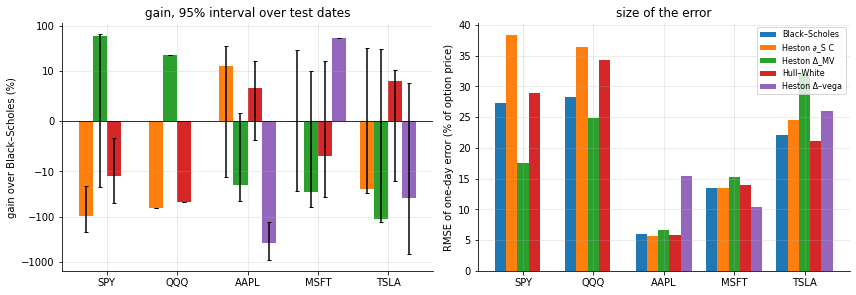

In [19]:
tick, col = list(res), plt.cm.tab10.colors
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for j, m in enumerate(METHODS):
    g, lo, hi = (np.array([100 * res[t][c][m] for t in tick], float) for c in ("gain", "lo", "hi"))
    if j:                                                      # Black–Scholes is the baseline: its gain is 0 by definition
        ax[0].bar(np.arange(len(tick)) + (j - 2.5) * 0.2, g, 0.2, color=col[j], capsize=2,
                  yerr=np.clip(np.nan_to_num([g - lo, hi - g]), 0, None))
    ax[1].bar(np.arange(len(tick)) + (j - 2) * 0.16, [100 * res[t].rmse[m] for t in tick], 0.16, color=col[j], label=m)
ax[0].set_yscale("symlog", linthresh=10)                       # gains are at most 100% but unbounded below
ax[0].yaxis.set_major_formatter(plt.matplotlib.ticker.ScalarFormatter())
ax[0].set(ylabel="gain over Black–Scholes (%)", title="gain, 95% interval over test dates")
ax[1].set(ylabel="RMSE of one-day error (% of option price)", title="size of the error")
for a_ in ax:
    a_.set_xticks(np.arange(len(tick)), tick)
ax[0].axhline(0, color="k", lw=0.8); ax[1].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURE_DIR / "five_ticker_hedges.png", dpi=150); plt.show()

**Heston parameters on the market data** (median over dates). The correlation $\rho$ is the quantity the minimum-variance and Hull–White corrections rely on.

In [20]:
pt = pd.DataFrame({t: X.median() for t, X in par.items()}).T
pt["Feller fails"] = [(2 * X.kappa * X.theta < X.xi**2).mean() for X in par.values()]
pt.round(3)

,v0,kappa,theta,xi,rho,Feller fails
SPY,0.021,6.039,0.046,1.568,-0.605,1.000
QQQ,0.077,5.217,0.078,2.059,-0.304,1.000
AAPL,0.048,3.946,0.094,0.650,-0.380,0.315
MSFT,0.072,3.884,0.120,0.629,-0.255,0.353
TSLA,0.169,3.875,0.268,2.010,0.084,0.773
